# 00 Data
Downloads daily prices for the 24 symbols, saves them once to `data/prices.parquet`, and checks them.
Later notebooks read the saved file with `load_prices()` instead of downloading again.

Plain-language key: **adjusted close** = closing price with dividends added back in (the "total return" price). **Raw close** = the price actually quoted.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import config
from rotation.data import download_prices, validate_prices, load_prices, wide
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)
config.DATA_DIR.mkdir(exist_ok=True); config.RESULTS_DIR.mkdir(exist_ok=True)
print(len(config.ALL_SYMBOLS), "symbols; history from", config.START)

24 symbols; history from 1999-01-01


## 1. Download and save
One symbol at a time. If any symbol is empty, stale or broken, `validate_prices` raises an error and we stop (no switching data sources).

In [2]:
raw = download_prices()
validate_prices(raw)
raw.to_parquet(config.PRICES_FILE, index=False)
print("saved", config.PRICES_FILE, raw.shape)

SPY        6989 rows


XLK        6989 rows


XLE        6989 rows


XLV        6989 rows


XLU        6989 rows


...

TLT        6093 rows


USO        5162 rows


UUP        4939 rows


EEM        5915 rows


BTC-USD    4412 rows
saved C:\Users\joyfu\Documents\market-rotation-research\data\prices.parquet (141083, 8)


## 2. Reload from the saved file
Proves the read path later notebooks will use.

In [3]:
df = load_prices()
print(df.symbol.nunique(), "symbols,", len(df), "rows")
df.head()

24 symbols, 141083 rows


,date,symbol,open,high,low,close,adj_close,volume
0,2014-09-17,BTC-USD,465.864014,468.174011,452.421997,457.334015,457.334015,21056800
1,2014-09-18,BTC-USD,456.859985,456.859985,413.104004,424.440002,424.440002,34483200
2,2014-09-19,BTC-USD,424.102997,427.834991,384.532013,394.795990,394.795990,37919700
3,2014-09-22,BTC-USD,399.100006,406.915985,397.130005,402.152008,402.152008,24127600
4,2014-09-23,BTC-USD,402.092010,441.557007,396.196991,435.790985,435.790985,45099500


## 3. Coverage and missing days
Missing day = a day SPY traded, between a symbol's own first and last date, where that symbol has no adjusted close.

In [4]:
adj = wide(df, "adj_close"); cls = wide(df, "close")
cal = adj["SPY"].dropna().index
rows = {}
for s in config.ALL_SYMBOLS:
    a = adj[s].dropna()
    inside = cal[(cal >= a.index[0]) & (cal <= a.index[-1])]
    missing = inside.difference(a.index)
    rows[s] = dict(group=config.GROUP[s], first_date=a.index[0].date(), last_date=a.index[-1].date(),
                   trading_days=len(a), missing_days=len(missing))
    if 0 < len(missing) <= 10:
        print(s, "missing:", [d.date().isoformat() for d in missing])
summary = pd.DataFrame(rows).T
summary

,group,first_date,last_date,trading_days,missing_days
SPY,benchmark,1999-01-04,2026-10-15,6989,0
XLK,sector,1999-01-04,2026-10-15,6989,0
XLE,sector,1999-01-04,2026-10-15,6989,0
XLV,sector,1999-01-04,2026-10-15,6989,0
XLU,sector,1999-01-04,2026-10-15,6989,0
XLF,sector,1999-01-04,2026-10-15,6989,0
XLI,sector,1999-01-04,2026-10-15,6989,0
XLB,sector,1999-01-04,2026-10-15,6989,0
XLP,sector,1999-01-04,2026-10-15,6989,0
XLY,sector,1999-01-04,2026-10-15,6989,0


## 4. Big moves (more than 15% in one day, adjusted close)
Listed so you can judge real move vs data error. Note: BTC-USD's Monday change spans the weekend because non-trading days were dropped.

In [5]:
ret = adj.pct_change(fill_method=None)
big = ret.stack().rename("return").reset_index()
big.columns = ["date", "symbol", "return"]
big = big[big["return"].abs() > config.BIG_MOVE].copy()
prev = adj.shift(1).stack().rename("prev_adj_close")
cur = adj.stack().rename("adj_close")
vol = wide(df, "volume").stack().rename("volume")
big = big.set_index(["date", "symbol"]).join([prev, cur, vol]).reset_index().sort_values(["symbol", "date"])
big["return"] = (big["return"] * 100).round(1)
big.to_csv(config.RESULTS_DIR / "00_big_moves.csv", index=False)
summary["big_moves"] = big.groupby("symbol").size().reindex(summary.index).fillna(0).astype(int)
print(len(big), "big-move days")
big

59 big-move days


,date,symbol,return,prev_adj_close,adj_close,volume
18,2014-11-12,BTC-USD,15.2,367.695007,423.561005,4.578320e+07
19,2015-01-13,BTC-USD,-15.7,267.795990,225.860992,7.284390e+07
20,2015-01-14,BTC-USD,-21.1,225.860992,178.102997,9.763870e+07
21,2015-01-15,BTC-USD,17.8,178.102997,209.843994,8.177350e+07
22,2015-01-26,BTC-USD,17.4,232.878998,273.472992,1.067940e+08
23,2015-08-18,BTC-USD,-18.2,257.976013,211.078995,4.214720e+07
24,2016-01-15,BTC-USD,-15.3,430.306000,364.330994,1.533510e+08
25,2016-06-13,BTC-USD,22.0,577.469971,704.375977,2.432950e+08
26,2017-07-20,BTC-USD,23.9,2273.429932,2817.600098,2.249260e+09
27,2017-08-07,BTC-USD,16.7,2895.889893,3378.939941,1.482280e+09


## 5. Adjusted vs raw close
Last-day gap = raw close vs adjusted close on the final day. Yahoo adjusts history backwards from today, so the gap is ~0 on the last day and grows going back in time. So we also show the **first-day gap** and **price-only vs total return** (raw vs adjusted) over each fund's whole history; that difference is the dividend effect.

In [6]:
def gap(s, i):
    a = adj[s].dropna(); d = a.index[i]
    return (cls.loc[d, s] / a.iloc[i] - 1) * 100
for s in summary.index:
    a = adj[s].dropna(); c = cls[s].dropna()
    summary.loc[s, "last_close"] = round(c.iloc[-1], 2)
    summary.loc[s, "last_adj_close"] = round(a.iloc[-1], 2)
    summary.loc[s, "last_day_gap_pct"] = round(gap(s, -1), 3)
    summary.loc[s, "first_day_gap_pct"] = round(gap(s, 0), 2)
    summary.loc[s, "price_return_pct"] = round((c.iloc[-1] / c.iloc[0] - 1) * 100, 1)
    summary.loc[s, "total_return_pct"] = round((a.iloc[-1] / a.iloc[0] - 1) * 100, 1)
summary.index.name = "symbol"
summary.to_csv(config.RESULTS_DIR / "00_data_summary.csv")
summary

,group,first_date,last_date,trading_days,missing_days,big_moves,last_close,last_adj_close,last_day_gap_pct,first_day_gap_pct,price_return_pct,total_return_pct
symbol,,,,,,,,,,,,
SPY,benchmark,1999-01-04,2026-10-15,6989,0,0,771.79,771.79,0.0,61.71,527.3,914.4
XLK,sector,1999-01-04,2026-10-15,6989,0,1,189.19,189.19,0.0,34.70,1046.6,1444.5
XLE,sector,1999-01-04,2026-10-15,6989,0,4,66.56,66.56,0.0,105.46,470.6,1072.4
XLV,sector,1999-01-04,2026-10-15,6989,0,0,177.19,177.19,0.0,50.32,583.1,926.9
XLU,sector,1999-01-04,2026-10-15,6989,0,0,41.65,41.65,0.0,159.24,180.0,625.9
XLF,sector,1999-01-04,2026-10-15,6989,0,6,55.27,55.27,0.0,70.84,190.3,395.9
XLI,sector,1999-01-04,2026-10-15,6989,0,0,167.89,167.89,0.0,62.15,593.2,1024.0
XLB,sector,1999-01-04,2026-10-15,6989,0,0,50.56,50.56,0.0,83.65,366.9,757.5
XLP,sector,1999-01-04,2026-10-15,6989,0,0,86.68,86.68,0.0,92.04,221.8,518.0


## 6. Growth of $1 since 2015 (log scale)
Adjusted close, so dividends are included. Log scale so equal percentage moves look equal.

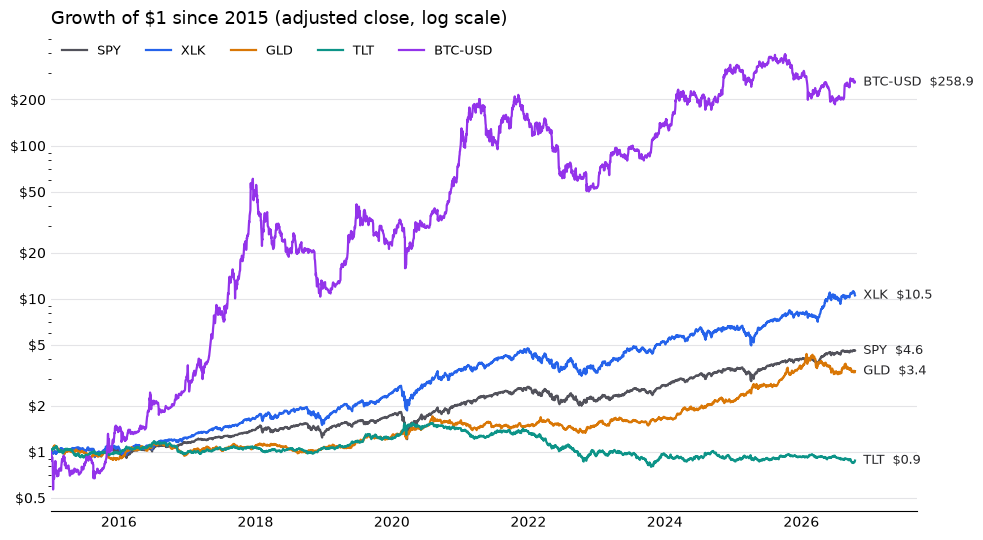

In [7]:
import matplotlib.pyplot as plt
from rotation.returns import growth_of_1
syms = ["SPY", "XLK", "GLD", "TLT", "BTC-USD"]
colors = {"SPY": "#52525b", "XLK": "#2563eb", "GLD": "#d97706", "TLT": "#0d9488", "BTC-USD": "#9333ea"}
g = growth_of_1(adj[syms], "2015-01-01")
fig, ax = plt.subplots(figsize=(10, 5.5))
for s in syms:
    ax.plot(g.index, g[s], lw=1.6, color=colors[s], label=s)
    ax.annotate(f"{s}  ${g[s].dropna().iloc[-1]:.1f}", (g.index[-1], g[s].dropna().iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#27272a")
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50, 100, 200])
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0)
ax.set_xlim(g.index[0], g.index[-1] + pd.Timedelta(days=330))
ax.set_title("Growth of $1 since 2015 (adjusted close, log scale)", loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper left", ncol=5, fontsize=9)
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / "00_growth_since_2015.png", dpi=150)
plt.show()

## 7. Final summary table

In [8]:
summary

,group,first_date,last_date,trading_days,missing_days,big_moves,last_close,last_adj_close,last_day_gap_pct,first_day_gap_pct,price_return_pct,total_return_pct
symbol,,,,,,,,,,,,
SPY,benchmark,1999-01-04,2026-10-15,6989,0,0,771.79,771.79,0.0,61.71,527.3,914.4
XLK,sector,1999-01-04,2026-10-15,6989,0,1,189.19,189.19,0.0,34.70,1046.6,1444.5
XLE,sector,1999-01-04,2026-10-15,6989,0,4,66.56,66.56,0.0,105.46,470.6,1072.4
XLV,sector,1999-01-04,2026-10-15,6989,0,0,177.19,177.19,0.0,50.32,583.1,926.9
XLU,sector,1999-01-04,2026-10-15,6989,0,0,41.65,41.65,0.0,159.24,180.0,625.9
XLF,sector,1999-01-04,2026-10-15,6989,0,6,55.27,55.27,0.0,70.84,190.3,395.9
XLI,sector,1999-01-04,2026-10-15,6989,0,0,167.89,167.89,0.0,62.15,593.2,1024.0
XLB,sector,1999-01-04,2026-10-15,6989,0,0,50.56,50.56,0.0,83.65,366.9,757.5
XLP,sector,1999-01-04,2026-10-15,6989,0,0,86.68,86.68,0.0,92.04,221.8,518.0
